In [ ]:
# Auto reload
%load_ext autoreload
%autoreload 2

In [ ]:
"""
Example usage of the PyFluesim package
Demonstrates the exact interface you requested
"""

# import sys
# import os
# #sys.path.append(os.path.join(os.path.dirname(__file__), 'pyfluesim'))

from flued_module import Chimney

# Define the chimney parts as requested
parts = [
    {
        'type': 'single',
        'inner_diameter_ft': 4/12,  # 4 inches converted to feet
        'height_ft': 7.5,
        'z_ft': 0,  # elevation above reference
        'thickness_w_m': 0.00076,  # wall thickness in meters
        'orientation': 'vertical',
        'density_w_kg_m3': 7850,  # density of wall material (steel)
        'cp_w_J_kg_K': 460,  # specific heat of wall material (steel)
        'k_w_W_m_K': 50,  # thermal conductivity of wall (steel)
        'film_w': 5.08e-5,  # max condensate film thickness in meters
        'epsilon_w': 0.8,  # emissivity of outer wall
        'T_ambient_K': 294.15,  # ambient temperature (21°C)
        'Pa': 101325,  # atmospheric pressure
        'num_segments': 5,
    }
]


In [ ]:
parts = [
      {
         # Bottom section - single wall (existing)
          'type': 'single',
          'inner_diameter_ft': 4/12,  # 4 inches converted to feet
          'height_ft': 7.5,
          'z_ft': 0,  # elevation above reference
          'thickness_w_m': 0.00076,  # wall thickness in meters
          'orientation': 'vertical',
          'density_w_kg_m3': 7850,  # density of wall material (steel)
          'cp_w_J_kg_K': 460,  # specific heat of wall material (steel)
          'k_w_W_m_K': 50,  # thermal conductivity of wall (steel)
          'film_w': 5.08e-5,  # max condensate film thickness in meters
          'epsilon_w': 0.8,  # emissivity of outer wall
          'T_ambient_K': 294.15,  # ambient temperature (21°C)
          'Pa': 101325,  # atmospheric pressure
          'num_segments': 5,
      },
      {
          # Top section - triple wall 
          'type': 'triple',
          'inner_diameter_ft': 4/12,  # Same diameter as bottom section
          'height_ft': 5.0,  # Height of triple wall section
          'z_ft': 7.5,  # Starts where single wall ends
          'orientation': 'vertical',
          'T_ambient_K': 273.15,  # ambient temperature (21°C)
          'Pa': 101325,  # atmospheric pressure
          'num_segments': 4,  # num_segments_triple_layer

          # Inner wall (liner) properties - wall1
          'thickness_inner_m': 0.0005,  # triple_layer_T1_thickness_m
          'density_inner_kg_m3': 8000,  # wall1_density_kg_m3
          'cp_inner_J_kg_K': 500,       # wall1_cp_J_kg_K
          'k_inner_W_m_K': 16,          # wall1_k_W_m_K
          'epsilon_inner': 0.3,         # Lower emissivity for inner stainless steel

          # Middle layer (insulation) properties - wall2
          'thickness_middle_m': 0.0244,  # triple_layer_T2_thickness_m = 0.0254 - (0.0005 * 2)
          'density_middle_kg_m3': 150,   # wall2_density_kg_m3
          'cp_middle_J_kg_K': 1050,      # wall2_cp_J_kg_K
          'k_middle_W_m_K': 0.05,        # wall2_k_W_m_K

          # Outer wall properties - wall3
          'thickness_outer_m': 0.0005,   # triple_layer_T3_thickness_m
          'density_outer_kg_m3': 8000,   # wall3_density_kg_m3
          'cp_outer_J_kg_K': 500,        # wall3_cp_J_kg_K
          'k_outer_W_m_K': 16,           # wall3_k_W_m_K
          'epsilon_outer': 0.8,          # emissivity of outer wall

          # Air gaps (no gaps specified, so set to 0)
          'air_gap_inner_m': 0.0,        # No air gap between liner and insulation
          'air_gap_outer_m': 0.0,        # No air gap between insulation and outer wall

          # Additional properties
          'film_w': 5.08e-5,             # max condensate film thickness
          'has_fittings': False,         # augmentation for fittings
          'roughness_m': 1e-6,           # surface roughness
          'humidity_ratio': 0.01,        # kg water / kg dry air
      }
  ]
# Create and run the simulation
chimney = Chimney(parts=parts, dt=1, total_time=1200)


DEBUG: Initializing conditions for 2 parts
DEBUG: Part 1 (single), segments 0-4, T_ambient=21.0°C
DEBUG: Single wall initialized - T_wall[0,0] = 21.0°C
DEBUG: Part 2 (triple), segments 5-8, T_ambient=0.0°C
DEBUG: Triple wall initialized - T_liner[0,5] = 0.0°C


In [ ]:
# parts = [
#       {
#           # First section: 7.5 ft vertical
#           'type': 'single',  # or 'triple' depending on wall construction
#           'inner_diameter_ft': 4/12,  # 4 inches
#           'height_ft': 7.5,
#           'z_ft': 0,  # starts at ground level
#           'orientation': 'vertical',
#           'thickness_w_m': 0.00076,
#           'density_w_kg_m3': 7850,
#           'cp_w_J_kg_K': 460,
#           'k_w_W_m_K': 50,
#           'film_w': 5.08e-5,
#           'epsilon_w': 0.8,
#           'T_ambient_K': 294.15,
#           'Pa': 101325,
#           'num_segments': 5,
#           'has_fittings': False,
#           'roughness_m': 1e-6,
#           'humidity_ratio': 0.01,
#       },
#       {
#           # Second section: 2 ft horizontal connector
#           'type': 'single',
#           'inner_diameter_ft': 4/12,
#           'height_ft': 2.0,  # "height" = length for horizontal
#           'z_ft': 7.5,  # elevation stays at 7.5 ft
#           'orientation': 'horizontal',
#           'thickness_w_m': 0.00076,
#           'density_w_kg_m3': 7850,
#           'cp_w_J_kg_K': 460,
#           'k_w_W_m_K': 50,
#           'film_w': 5.08e-5,
#           'epsilon_w': 0.8,
#           'T_ambient_K': 294.15,
#           'Pa': 101325,
#           'num_segments': 2,
#           'has_fittings': True,  # usually has elbows at ends
#           'roughness_m': 1e-6,
#           'humidity_ratio': 0.01,
#       },
#       {
#           # Third section: 3 ft vertical (could be triple wall)
#           'type': 'triple',  # example with insulated pipe
#           'inner_diameter_ft': 4/12,
#           'height_ft': 3.0,
#           'z_ft': 7.5,  # still at 7.5 ft elevation (horizontal doesn't add height)
#           'orientation': 'vertical',
#           'T_ambient_K': 294.15,
#           'Pa': 101325,
#           'num_segments': 3,
#           # Triple wall properties
#           'thickness_inner_m': 0.0008,
#           'density_inner_kg_m3': 8000,
#           'cp_inner_J_kg_K': 500,
#           'k_inner_W_m_K': 16,
#           'epsilon_inner': 0.3,
#           'thickness_middle_m': 0.025,
#           'density_middle_kg_m3': 100,
#           'cp_middle_J_kg_K': 1050,
#           'k_middle_W_m_K': 0.04,
#           'thickness_outer_m': 0.001,
#           'density_outer_kg_m3': 7850,
#           'cp_outer_J_kg_K': 460,
#           'k_outer_W_m_K': 50,
#           'epsilon_outer': 0.8,
#           'has_fittings': False,
#           'roughness_m': 1e-6,
#           'humidity_ratio': 0.01,
#       }
#   ]

# # Create and run the simulation
# chimney = Chimney(parts=parts, dt=1, total_time=1200)


DEBUG: Initializing conditions for 3 parts
DEBUG: Part 1 (single), segments 0-4, T_ambient=21.0°C
DEBUG: Single wall initialized - T_wall[0,0] = 21.0°C
DEBUG: Part 2 (single), segments 5-6, T_ambient=21.0°C
DEBUG: Single wall initialized - T_wall[0,5] = 21.0°C
DEBUG: Part 3 (triple), segments 7-9, T_ambient=21.0°C
DEBUG: Triple wall initialized - T_liner[0,7] = 21.0°C


In [4]:
import time 
tok=time.time()
print("Running chimney simulation...")
print(f"Configuration: {len(chimney.parts)} parts, {chimney.total_segments} total segments")
print(f"Time step: {chimney.dt}s, Total time: {chimney.total_time}s")

# Run the simulation
chimney.run_simulation(save_interval=5)
tik=time.time()
print(f'Simulation took {tik-tok:.2f} seconds')

Running chimney simulation...
Configuration: 2 parts, 9 total segments
Time step: 1s, Total time: 1200s
Starting comprehensive heat transfer simulation:
  9 segments, 1200 time steps
  Time step: 1s, Total time: 1200s

*** Diagnostics at t=1.0s (step 1) ***
ERROR: Wall temperature 1.1°C below ambient at segment 5
ERROR: Liner temperature 1.1°C below ambient

*** Diagnostics at t=2.0s (step 2) ***
ERROR: Wall temperature 2.2°C below ambient at segment 5
ERROR: Liner temperature 2.2°C below ambient

*** Diagnostics at t=3.0s (step 3) ***
ERROR: Wall temperature 3.3°C below ambient at segment 5
ERROR: Liner temperature 3.3°C below ambient

*** Diagnostics at t=4.0s (step 4) ***
ERROR: Wall temperature 4.5°C below ambient at segment 5
ERROR: Liner temperature 4.5°C below ambient

*** Diagnostics at t=5.0s (step 5) ***
ERROR: Wall temperature 5.4°C below ambient at segment 8
ERROR: Liner temperature 5.4°C below ambient

*** Diagnostics at t=6.0s (step 6) ***
ERROR: Gas temperature 19.6°C be

c:\Users\Ana\OneDrive - LBNL\Documents\WH\flued_dynamics\flued_module\condensation_physics.py:65: RuntimeWarning: overflow encountered in scalar power
  return 10**(log10_p_kPa) * 1000  # Convert kPa to Pa


   20.0% | t= 240.0s | Gas: 243.7-284.8°C | Wall: 166.9-227.2°C
   25.0% | t= 300.0s | Gas: 277.0-323.8°C | Wall: 190.3-262.5°C


c:\Users\Ana\OneDrive - LBNL\Documents\WH\flued_dynamics\flued_module\condensation_physics.py:65: RuntimeWarning: overflow encountered in scalar multiply
  return 10**(log10_p_kPa) * 1000  # Convert kPa to Pa


   30.0% | t= 360.0s | Gas: 307.9-355.7°C | Wall: 210.2-293.1°C
   35.0% | t= 420.0s | Gas: 334.0-381.9°C | Wall: 226.3-318.2°C
   40.0% | t= 480.0s | Gas: 355.1-403.3°C | Wall: 239.4-338.3°C
   45.0% | t= 540.0s | Gas: 372.4-420.8°C | Wall: 250.0-354.7°C
   50.0% | t= 600.0s | Gas: 386.6-435.2°C | Wall: 258.6-368.1°C
   55.0% | t= 660.0s | Gas: 398.1-446.9°C | Wall: 265.7-379.2°C
   60.0% | t= 720.0s | Gas: 407.6-456.5°C | Wall: 271.4-388.2°C
   65.0% | t= 780.0s | Gas: 415.4-464.4°C | Wall: 276.2-395.5°C
   70.0% | t= 840.0s | Gas: 421.8-470.9°C | Wall: 280.4-401.6°C
   75.0% | t= 900.0s | Gas: 427.1-476.2°C | Wall: 284.0-407.1°C
   80.0% | t= 960.0s | Gas: 431.6-480.5°C | Wall: 286.9-411.8°C
   85.0% | t=1020.0s | Gas: 435.2-484.0°C | Wall: 289.3-415.8°C
   90.0% | t=1080.0s | Gas: 438.2-486.9°C | Wall: 291.2-419.0°C
   95.0% | t=1140.0s | Gas: 440.7-489.3°C | Wall: 292.8-421.7°C
  100.0% | t=1200.0s | Gas: 442.7-491.2°C | Wall: 294.1-423.9°C
Comprehensive simulation completed succe

 5.0% | t=  60.0s | Gas:  81.7-107.8°C | Wall:  52.6- 61.8°C
   10.0% | t= 120.0s | Gas: 148.3-178.9°C | Wall:  98.8-127.3°C
  Warning: Coupling did not converge at t=180.0s
   15.0% | t= 180.0s | Gas: 201.3-237.1°C | Wall: 136.8-182.8°C
Output is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...
c:\Users\Ana\OneDrive - LBNL\Documents\WH\flued_dynamics\flued_module\condensation_physics.py:65: RuntimeWarning: overflow encountered in scalar power
  return 10**(log10_p_kPa) * 1000  # Convert kPa to Pa
   20.0% | t= 240.0s | Gas: 243.7-284.8°C | Wall: 166.9-227.2°C
   25.0% | t= 300.0s | Gas: 277.0-323.8°C | Wall: 190.3-262.5°C
c:\Users\Ana\OneDrive - LBNL\Documents\WH\flued_dynamics\flued_module\condensation_physics.py:65: RuntimeWarning: overflow encountered in scalar multiply
  return 10**(log10_p_kPa) * 1000  # Convert kPa to Pa
   30.0% | t= 360.0s | Gas: 307.9-355.7°C | Wall: 210.2-293.1°C
   35.0% | t= 420.0s | Gas: 334.0-381.9°C | Wall: 226.3-318.2°C
   40.0% | t= 480.0s | Gas: 355.1-403.3°C | Wall: 239.4-338.3°C
   45.0% | t= 540.0s | Gas: 372.4-420.8°C | Wall: 250.0-354.7°C
   50.0% | t= 600.0s | Gas: 386.6-435.2°C | Wall: 258.6-368.1°C
   55.0% | t= 660.0s | Gas: 398.1-446.9°C | Wall: 265.7-379.2°C
   60.0% | t= 720.0s | Gas: 407.6-456.5°C | Wall: 271.4-388.2°C
   65.0% | t= 780.0s | Gas: 415.4-464.4°C | Wall: 276.2-395.5°C
   70.0% | t= 840.0s | Gas: 421.8-470.9°C | Wall: 280.4-401.6°C
   75.0% | t= 900.0s | Gas: 427.1-476.2°C | Wall: 284.0-407.1°C
   80.0% | t= 960.0s | Gas: 431.6-480.5°C | Wall: 286.9-411.8°C
   85.0% | t=1020.0s | Gas: 435.2-484.0°C | Wall: 289.3-415.8°C
   90.0% | t=1080.0s | Gas: 438.2-486.9°C | Wall: 291.2-419.0°C
   95.0% | t=1140.0s | Gas: 440.7-489.3°C | Wall: 292.8-421.7°C
  100.0% | t=1200.0s | Gas: 442.7-491.2°C | Wall: 294.1-423.9°C
Comprehensive simulation completed successfully


In [5]:
import time 
tok=time.time()
print("Running chimney simulation...")
print(f"Configuration: {len(chimney.parts)} parts, {chimney.total_segments} total segments")
print(f"Time step: {chimney.dt}s, Total time: {chimney.total_time}s")

# Run the simulation
chimney.run_simulation(save_interval=5)
tik=time.time()
print(f'Simulation took {tik-tok:.2f} seconds')

Running chimney simulation...
Configuration: 2 parts, 9 total segments
Time step: 1s, Total time: 1200s
Starting comprehensive heat transfer simulation:
  9 segments, 1200 time steps
  Time step: 1s, Total time: 1200s

*** Diagnostics at t=1.0s (step 1) ***
ERROR: Wall temperature 1.1°C below ambient at segment 5
ERROR: Liner temperature 1.1°C below ambient

*** Diagnostics at t=2.0s (step 2) ***
ERROR: Wall temperature 2.2°C below ambient at segment 5
ERROR: Liner temperature 2.2°C below ambient

*** Diagnostics at t=3.0s (step 3) ***
ERROR: Wall temperature 3.3°C below ambient at segment 5
ERROR: Liner temperature 3.3°C below ambient

*** Diagnostics at t=4.0s (step 4) ***
ERROR: Wall temperature 4.5°C below ambient at segment 5
ERROR: Liner temperature 4.5°C below ambient

*** Diagnostics at t=5.0s (step 5) ***
ERROR: Wall temperature 5.4°C below ambient at segment 8
ERROR: Liner temperature 5.4°C below ambient

*** Diagnostics at t=6.0s (step 6) ***
ERROR: Gas temperature 19.6°C be

c:\Users\Ana\OneDrive - LBNL\Documents\WH\flued_dynamics\flued_module\condensation_physics.py:65: RuntimeWarning: overflow encountered in scalar power
  return 10**(log10_p_kPa) * 1000  # Convert kPa to Pa


   20.0% | t= 240.0s | Gas: 243.7-284.8°C | Wall: 166.9-227.2°C
   25.0% | t= 300.0s | Gas: 277.0-323.8°C | Wall: 190.3-262.5°C


c:\Users\Ana\OneDrive - LBNL\Documents\WH\flued_dynamics\flued_module\condensation_physics.py:65: RuntimeWarning: overflow encountered in scalar multiply
  return 10**(log10_p_kPa) * 1000  # Convert kPa to Pa


   30.0% | t= 360.0s | Gas: 307.9-355.7°C | Wall: 210.2-293.1°C
   35.0% | t= 420.0s | Gas: 334.0-381.9°C | Wall: 226.3-318.2°C
   40.0% | t= 480.0s | Gas: 355.1-403.3°C | Wall: 239.4-338.3°C
   45.0% | t= 540.0s | Gas: 372.4-420.8°C | Wall: 250.0-354.7°C
   50.0% | t= 600.0s | Gas: 386.6-435.2°C | Wall: 258.6-368.1°C
   55.0% | t= 660.0s | Gas: 398.1-446.9°C | Wall: 265.7-379.2°C
   60.0% | t= 720.0s | Gas: 407.6-456.5°C | Wall: 271.4-388.2°C
   65.0% | t= 780.0s | Gas: 415.4-464.4°C | Wall: 276.2-395.5°C
   70.0% | t= 840.0s | Gas: 421.8-470.9°C | Wall: 280.4-401.6°C
   75.0% | t= 900.0s | Gas: 427.1-476.2°C | Wall: 284.0-407.1°C
   80.0% | t= 960.0s | Gas: 431.6-480.5°C | Wall: 286.9-411.8°C
   85.0% | t=1020.0s | Gas: 435.2-484.0°C | Wall: 289.3-415.8°C
   90.0% | t=1080.0s | Gas: 438.2-486.9°C | Wall: 291.2-419.0°C
   95.0% | t=1140.0s | Gas: 440.7-489.3°C | Wall: 292.8-421.7°C
  100.0% | t=1200.0s | Gas: 442.7-491.2°C | Wall: 294.1-423.9°C
Comprehensive simulation completed succe

In [20]:

# Get summary results
summary = chimney.get_summary_data()
print("\nSimulation Results:")
print(f"Final gas temperature range: {summary['final_gas_temp_range_C'][0]:.1f} to {summary['final_gas_temp_range_C'][1]:.1f} °C")
print(f"Final wall temperature range: {summary['final_wall_temp_range_C'][0]:.1f} to {summary['final_wall_temp_range_C'][1]:.1f} °C")
print(f"Final mass flow rate: {summary['final_mass_flow_rate_kg_s']:.4f} kg/s")



Simulation Results:
Final gas temperature range: 442.7 to 491.2 °C
Final wall temperature range: 294.1 to 423.9 °C
Final mass flow rate: 0.0953 kg/s



Generating temperature profile plots...
DEBUG Part 2 Triple Wall:
  Final Liner temp: 421.9°C
  Final Middle temp: 53.6°C
  Final Outer temp: 53.6°C
  Ambient temp: 0.0°C


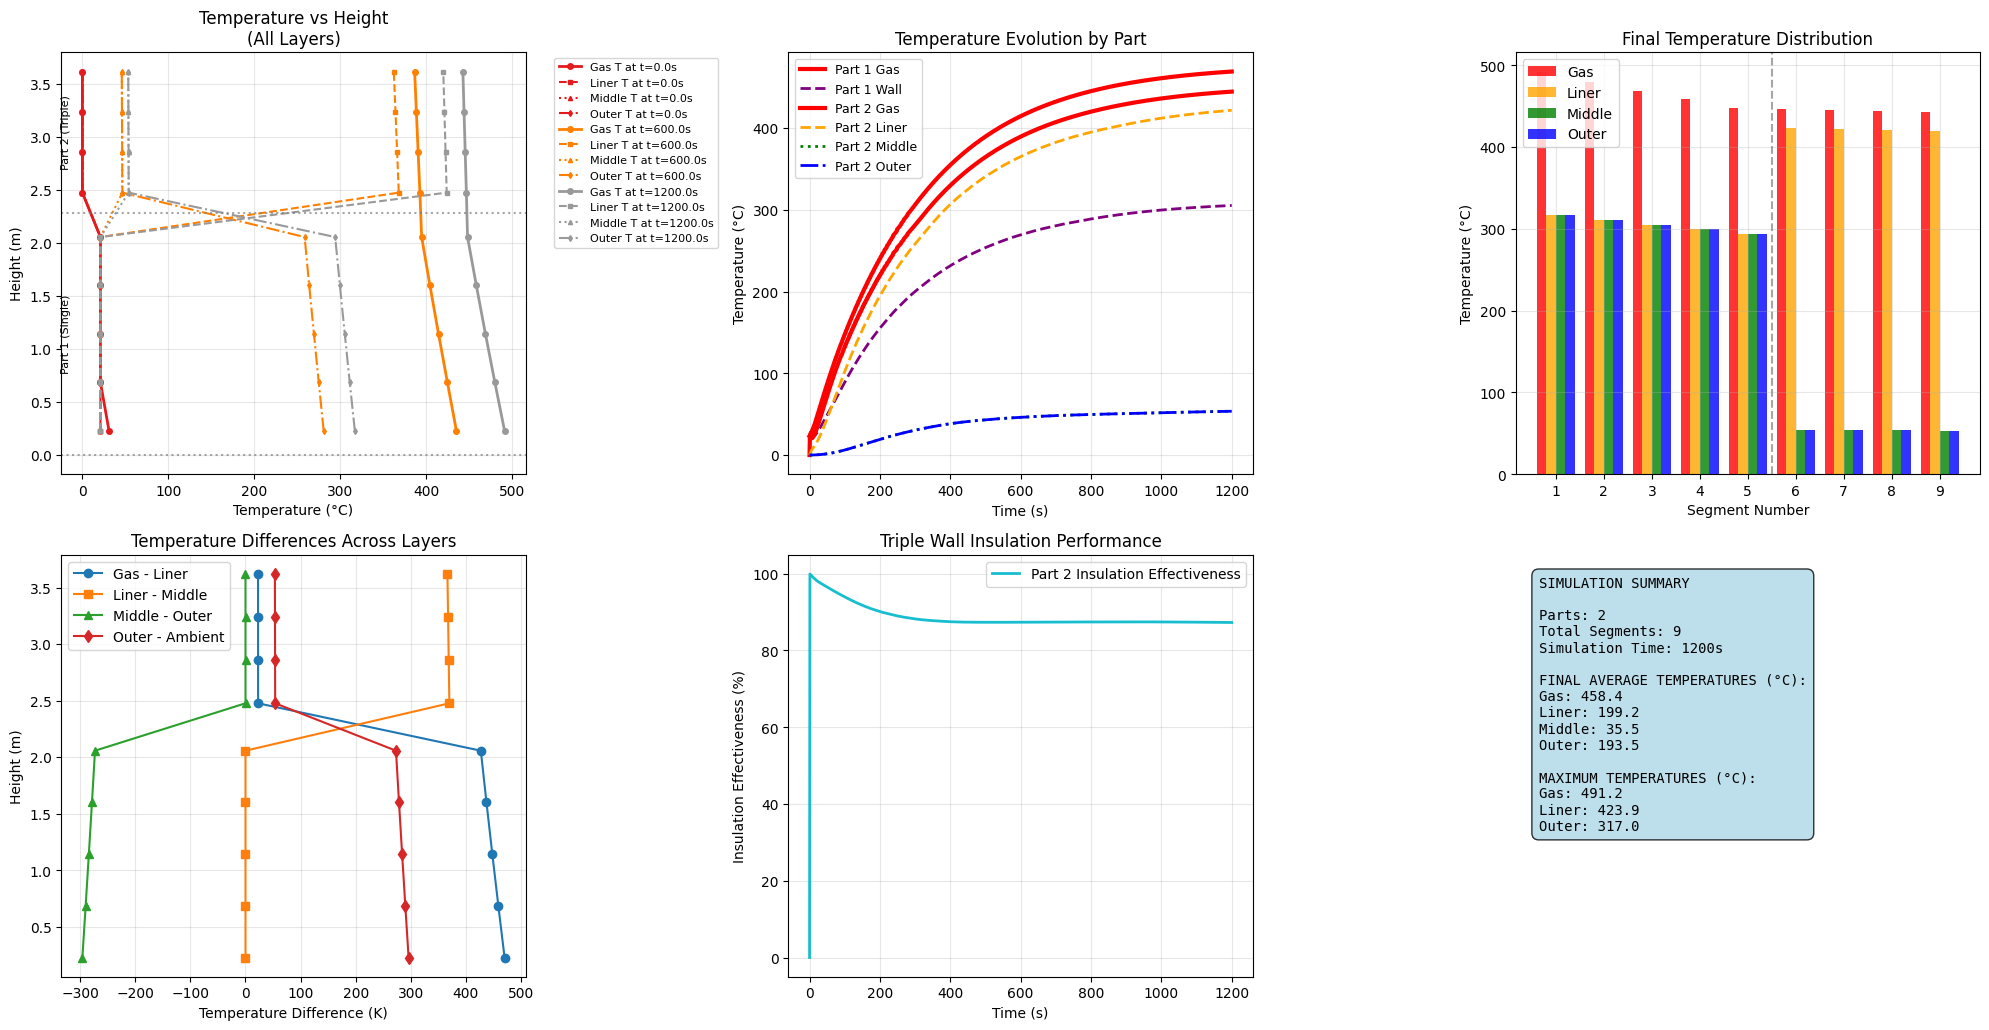


Generating segment-wise diagnostic plots...


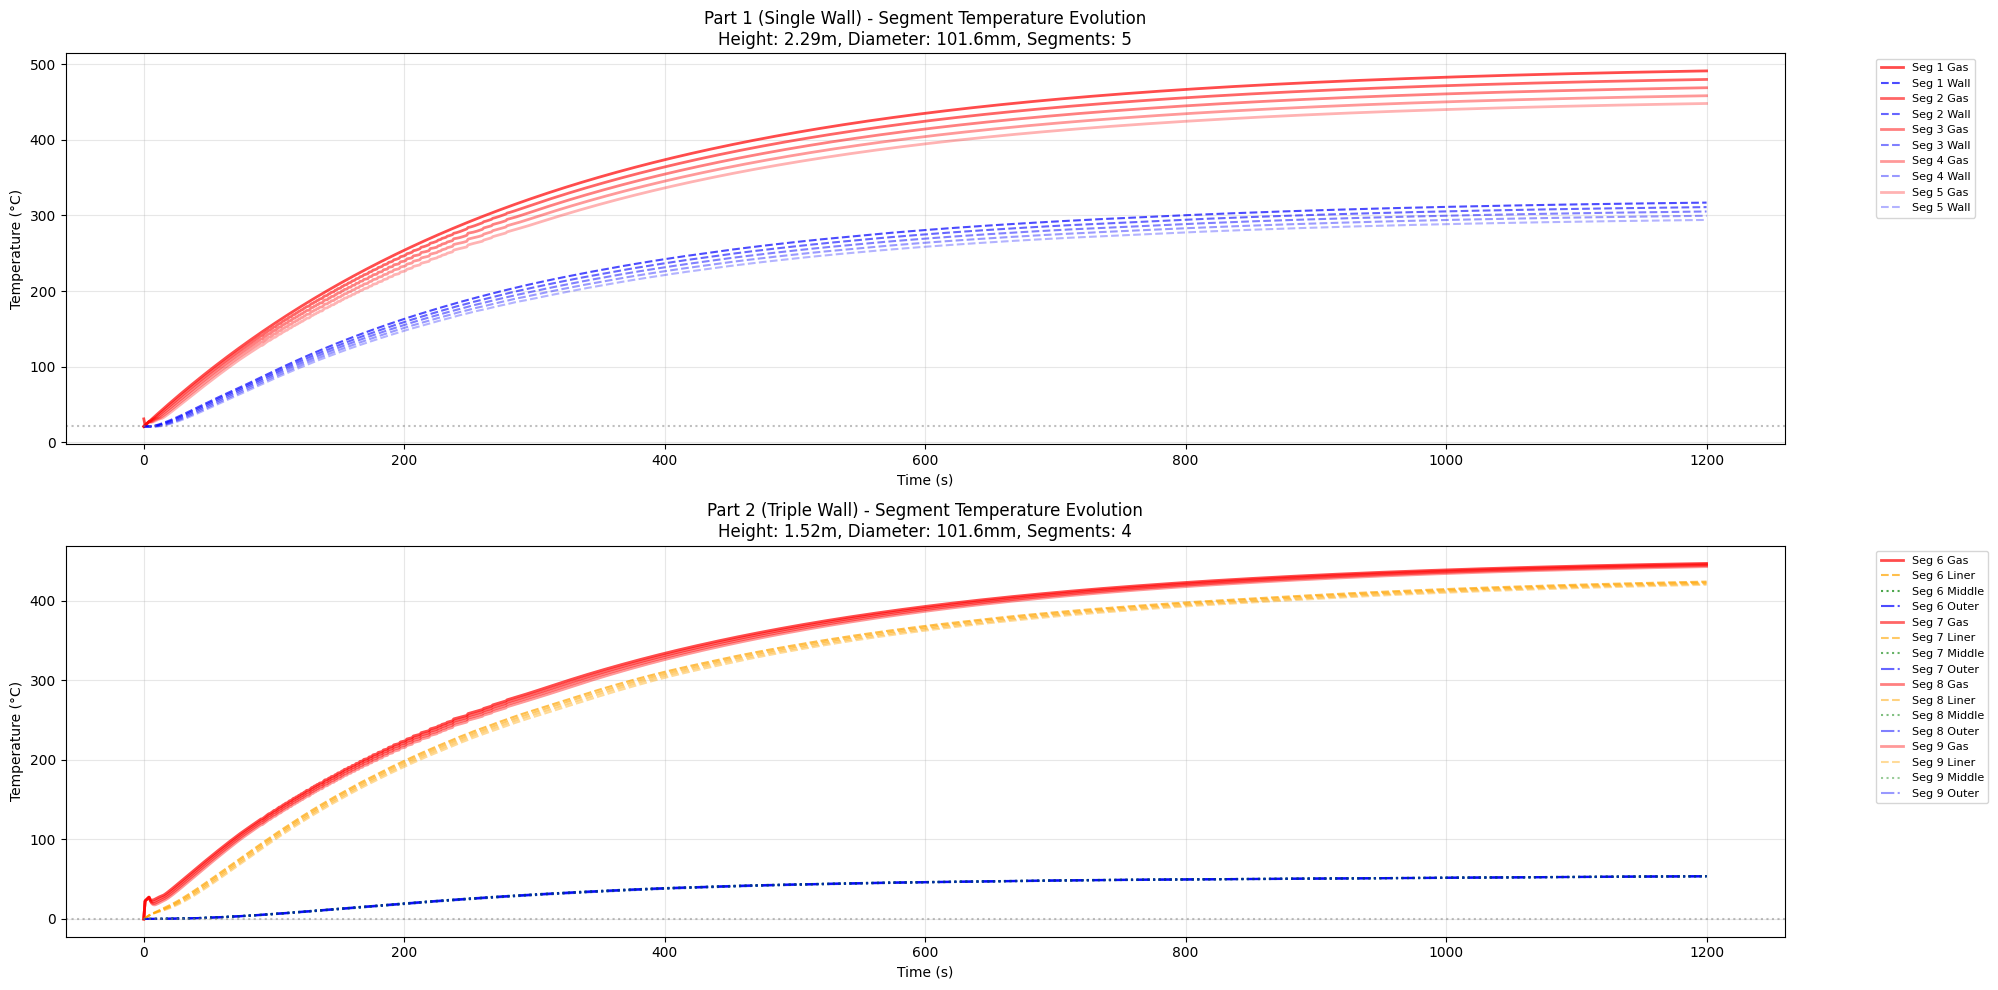

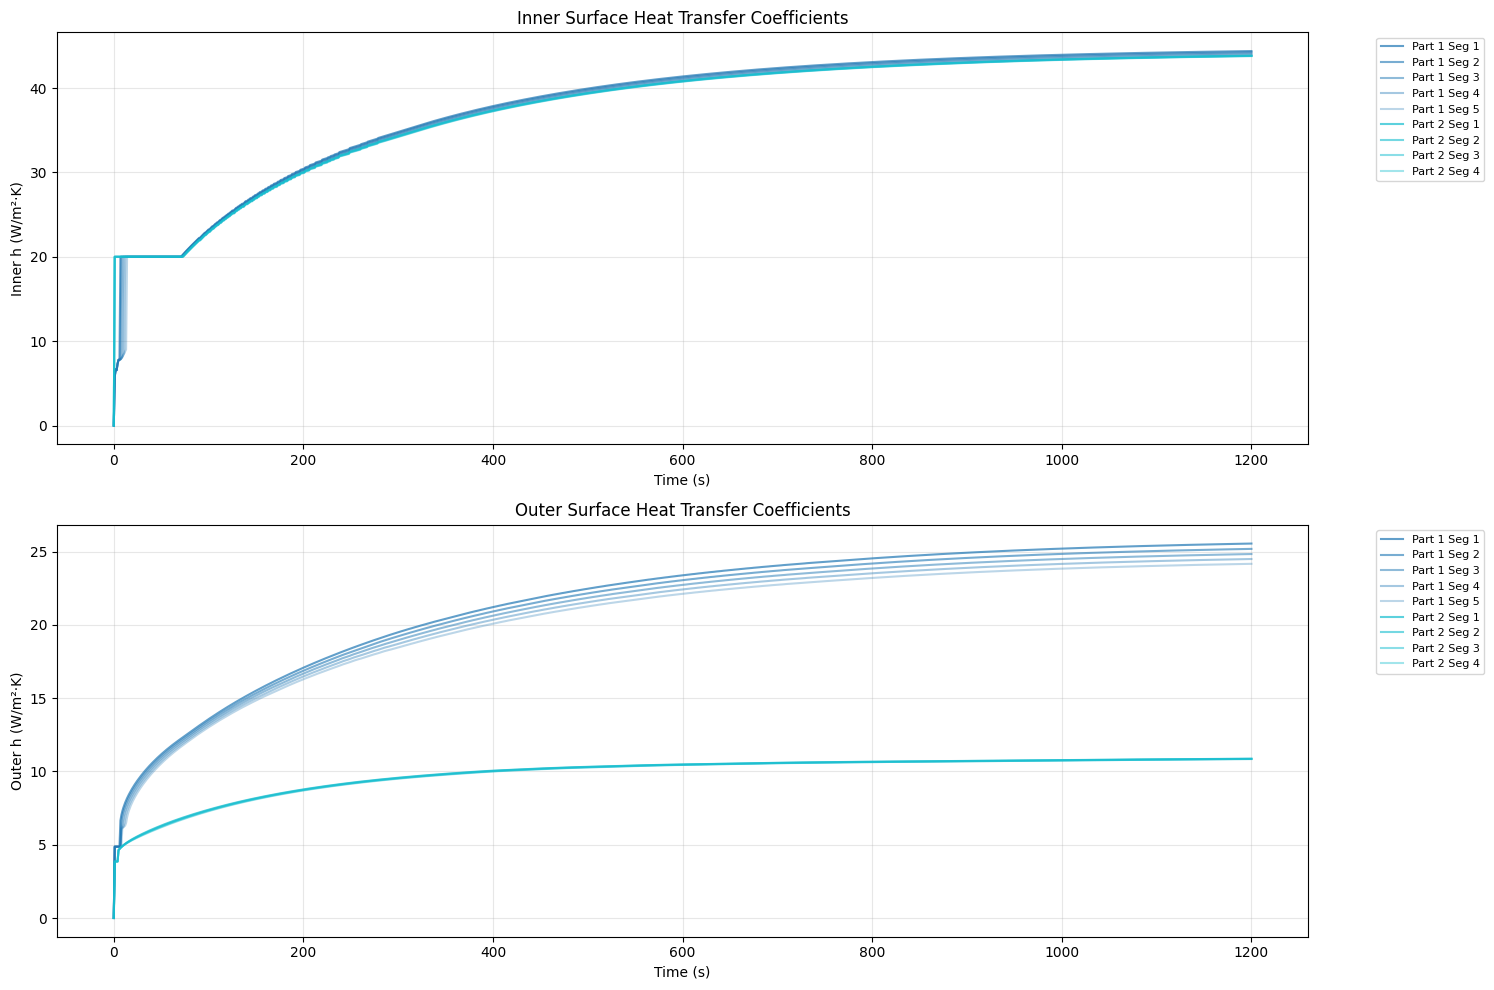


DETAILED SEGMENT INFORMATION

Part 1 (SINGLE WALL):
  Segments: 1 to 5
  Height: 2.29m
  Diameter: 101.6mm
  Final Gas Temperatures (°C): [491.22680897 479.93292824 468.98203629 458.386832   448.1317614 ]
  Final Wall Temperatures (°C): [317.02405966 311.08130187 305.28594239 299.63355213 294.11985066]

Part 2 (TRIPLE WALL):
  Segments: 6 to 9
  Height: 1.52m
  Diameter: 101.6mm
  Final Gas Temperatures (°C): [446.77934155 445.4270285  444.07475542 442.7224637 ]
  Final Liner Temperatures (°C): [423.89781029 422.57281521 421.24724687 419.92120277]
  Final Middle Temperatures (°C): [53.88211761 53.71774894 53.55075206 53.383358  ]
  Final Outer Temperatures (°C): [53.8633277  53.69902641 53.53209755 53.36477156]
  Temperature Reduction (Liner to Outer): 368.3°C
  Insulation Effectiveness: 87.3%

Simulation completed successfully!

Detailed results access:
Gas temperatures at final time (°C): [491.22680897 479.93292824 468.98203629 458.386832   448.1317614
 446.77934155 445.4270285  444

In [22]:

# Plot temperature profiles
print("\nGenerating temperature profile plots...")
chimney.plot_temperature_profiles()

print("\nSimulation completed successfully!")

# Example of accessing detailed data
print("\nDetailed results access:")
print(f"Gas temperatures at final time (°C): {chimney.T_gas[-1] - 273.15}")
print(f"Wall temperatures at final time (°C): {chimney.T_wall[-1] - 273.15}")
print(f"Mass flow rates over time (kg/s): min={chimney.mass_flow_rate.min():.4f}, max={chimney.mass_flow_rate.max():.4f}")

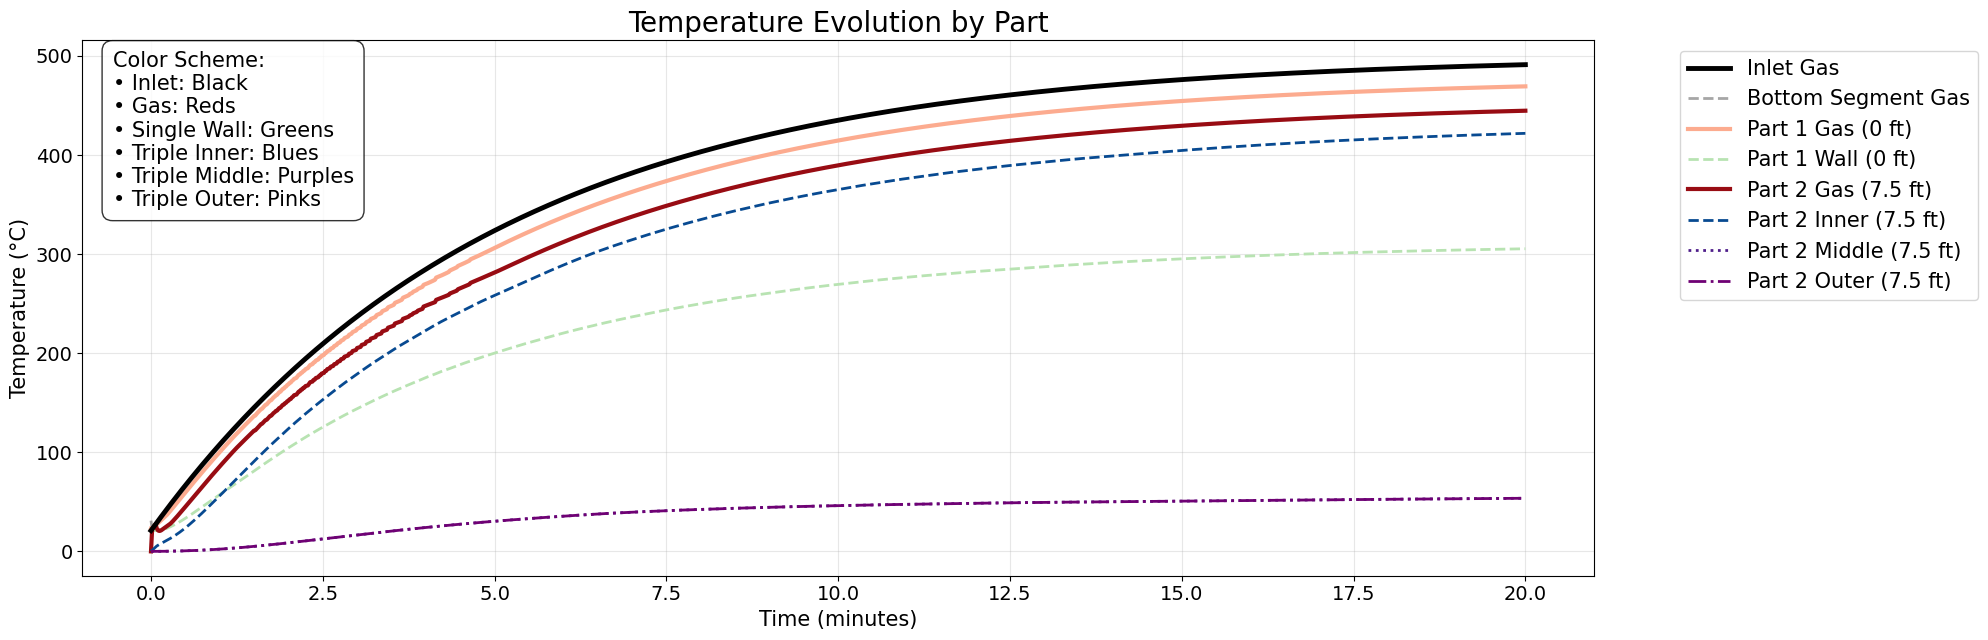

In [13]:
chimney.temp_evolution_by_part(ambient_temp=False)

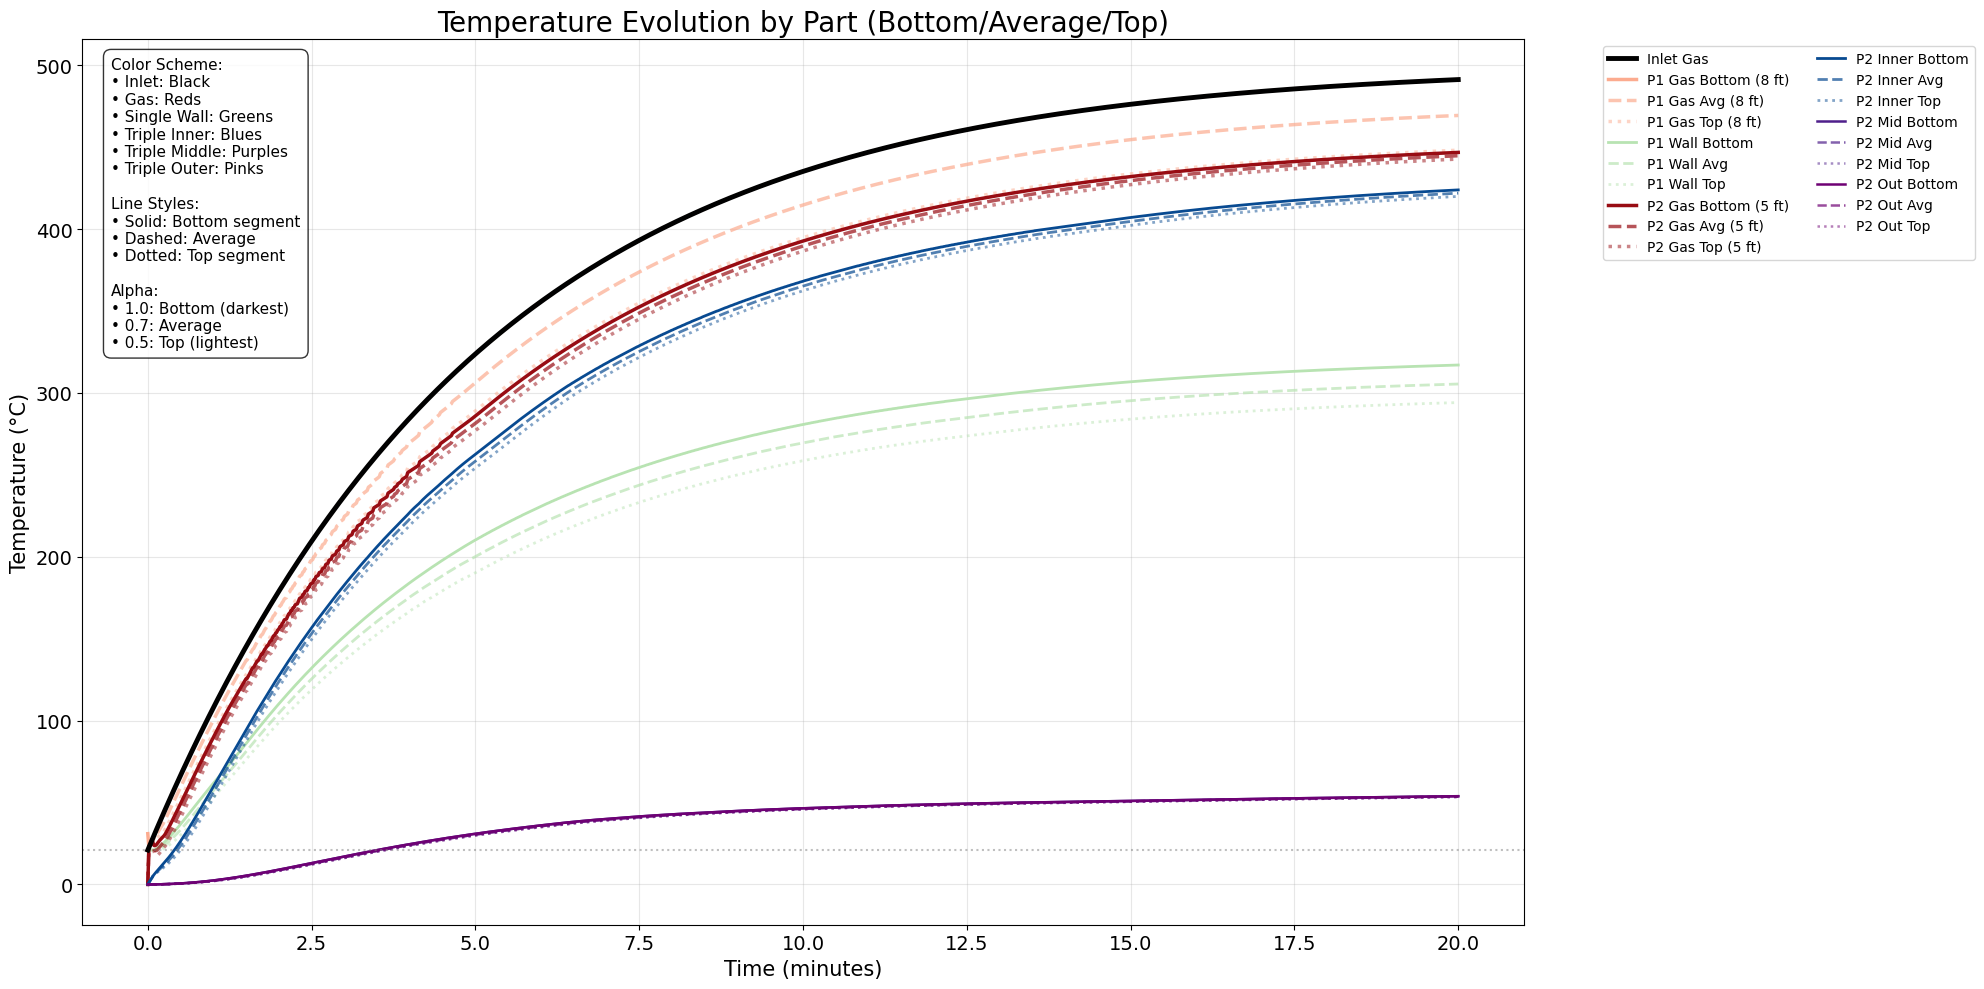

In [9]:
chimney.temp_evolution_br()

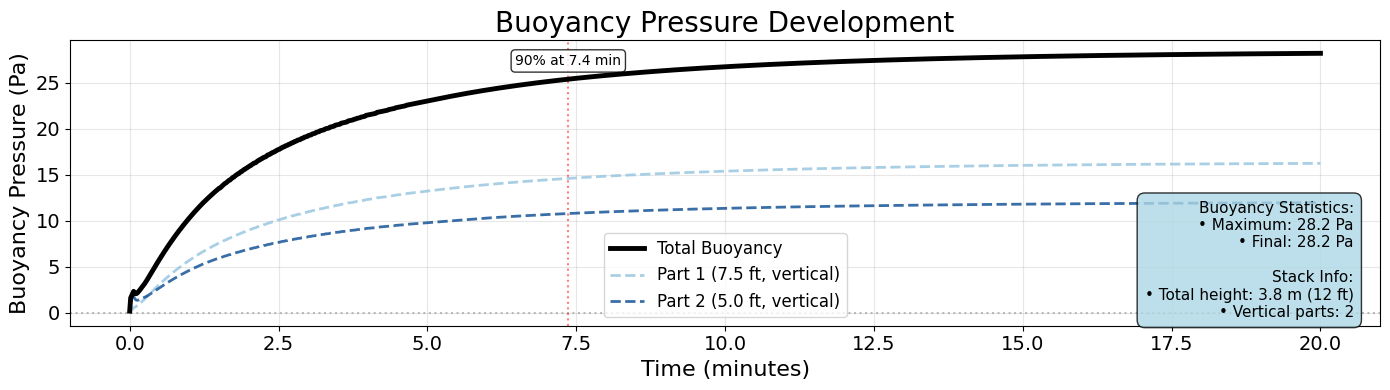

In [11]:
chimney.plot_buoyancy_pressure()

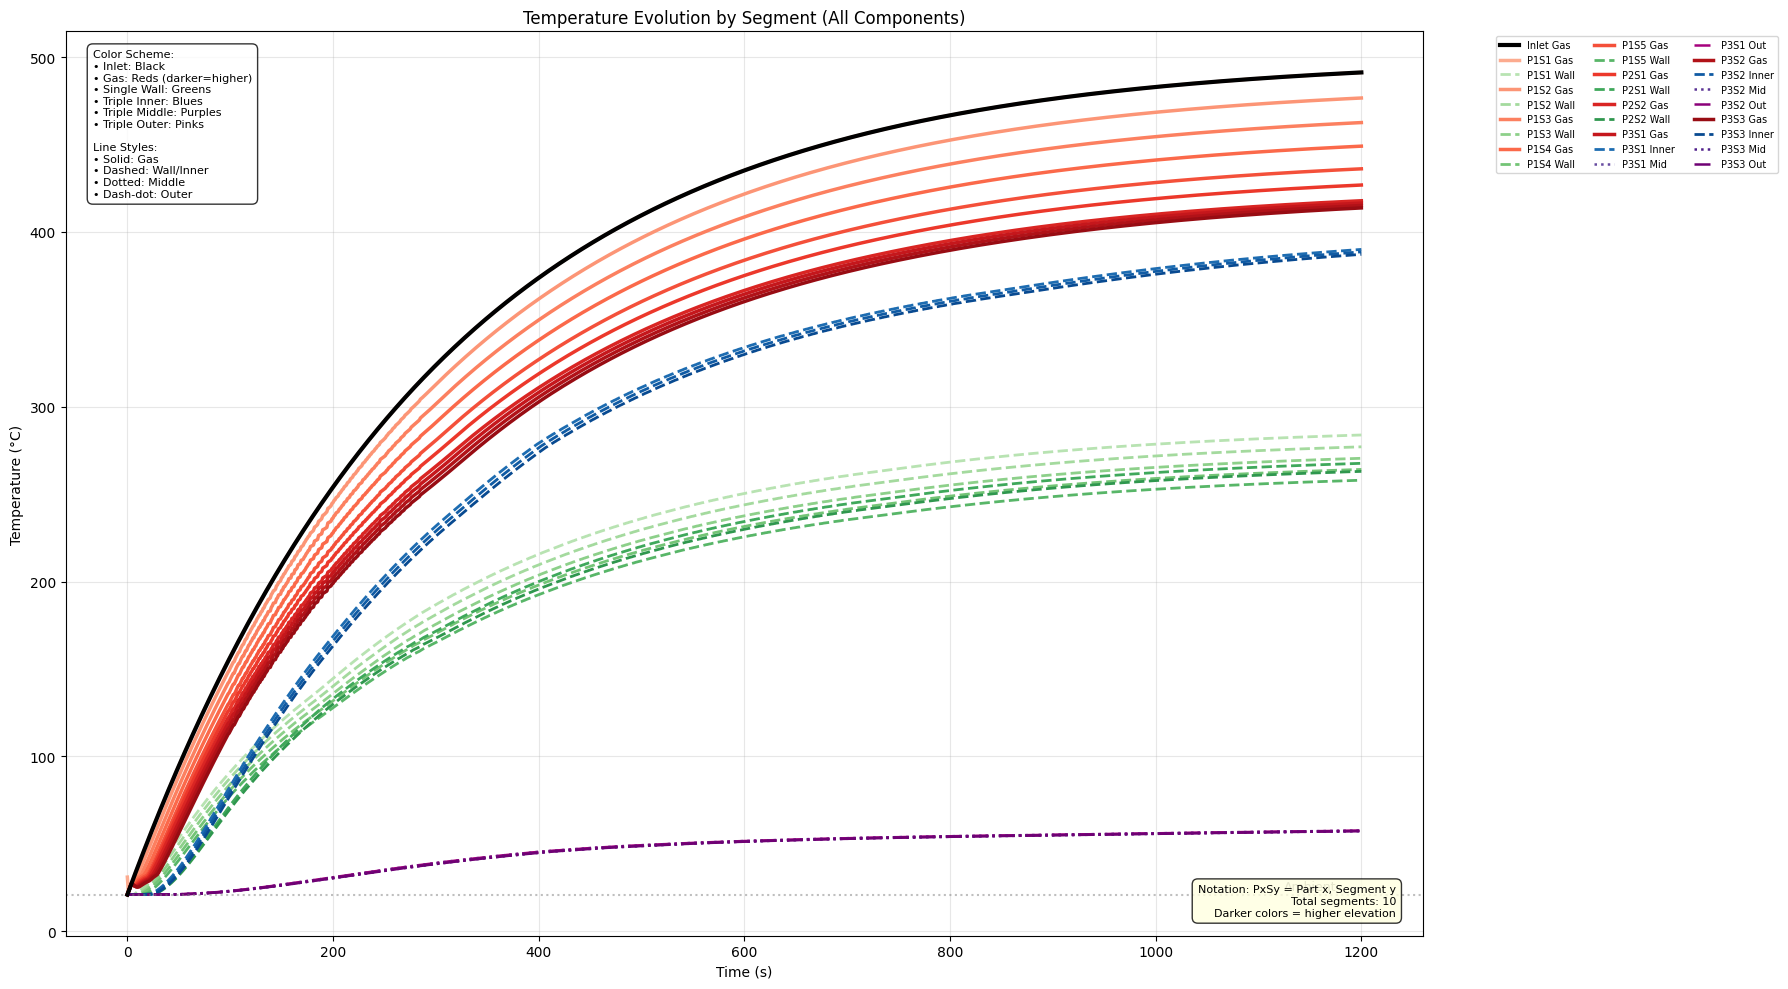

In [23]:
chimney.temp_evolution_by_segment()

In [ ]:

# Plot temperature profiles
print("\nGenerating temperature profile plots...")
chimney.plot_temperature_profiles()

print("\nSimulation completed successfully!")

# Example of accessing detailed data
print("\nDetailed results access:")
print(f"Gas temperatures at final time (°C): {chimney.T_gas[-1] - 273.15}")
print(f"Wall temperatures at final time (°C): {chimney.T_wall[-1] - 273.15}")
print(f"Mass flow rates over time (kg/s): min={chimney.mass_flow_rate.min():.4f}, max={chimney.mass_flow_rate.max():.4f}")